<a href="https://colab.research.google.com/github/bmiranda06/15466-gamefour/blob/main/Copy_of_lab8_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

https://tinyurl.com/f26-10301-lab-hw8

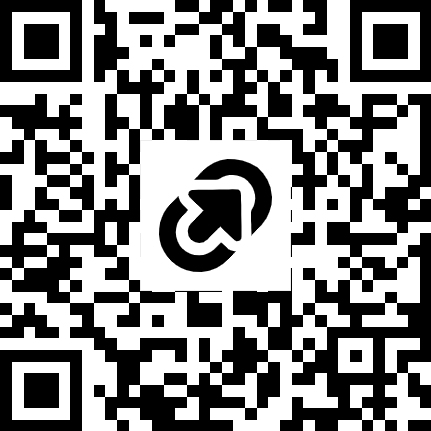

# Group members

- Partner 1's Name:
- Partner 1's Andrew ID:
- Partner 2's Name:
- Partner 2's Andrew ID:
- *(If assigned to a group of 3 by the course staff...)*
- Partner 3's Name:
- Partner 3's Andrew ID:


# Instructions

## The Rules
* *Grading:* For each problem posed in the Coding Lab, you will receive full credit if you have made a reasonable attempt (ideally correct, but not required to be so).
* *No AI assistance:* You are not allowed to use AI assistance during a Coding Lab.
* *Group size:* No groups of one person are allowed. You must be in a group of two, or directed by the course staff to be in a group of three. If you do not have a group, speak to the course staff.
* *Steps to follow:*
  1. Open the Colab notebook using the QR code. Then click File --> Save a Copy in Drive. Then click "Share" in the upper right corner and give your teammate(s) edit access.
  2. Fill in the name and Andrew ID of each of the group members in the cells above.
  3. Use the pair programming approach outlined below to complete the coding challenge(s).
  4. Follow the submission instructions below when you have completed the challenges. If you finish early, splendid! You are welcome to submit and leave when you have completed the work.

## On Pair Programming

- You will work in pairs with only a *single computer* open for the entire lab.
- Both partners are expected to be actively engaged at all times.
- **Roles:**
  - *Driver:* The driver controls the keyboard and mouse and writes the code. The driver focuses on translating ideas into correct, working code and should narrate what they are doing as they work.
  - *Navigator:* The navigator does not touch the keyboard. The navigator reviews the code in real time, thinks about correctness, edge cases, and overall strategy, and suggests improvements or alternative approaches.
- **Role Switching:**
  - Switch roles at least once during the 40-minute lab (roughly halfway through). You are welcome to switch *which* single computer is open at this point.
  - Make the switch promptly when instructed so that both partners experience both roles.
- **Collaboration Expectations:**
  - Discuss design decisions and bugs out loud.
  - Stay together on the same task; do not split the problem or work ahead independently.
  - Ensure both partners understand the solution by the end of the coding lab.

## Where to get help?

If you get stuck, don't panic! Just ask for help:

- Raise your hand and ask a member of the course staff. That is why we are here: to help you all!
- You are also welcome to ask questions of other groups. If the challenge requires a very small number of lines of code, we would recommend groups **do not** directly share code, **but instead** offer each other verbal hints when stuck.
- In some coding labs, the TAs might even decide to present a solution to the whole class. If you are still stuck when they do, you are welcome to live code along with them.

## **The Submission**
**Only one member of your group** should download this `.ipynb` file, and submit it on Gradescope to **Coding Lab: HW8**. As this is a group submission, make sure to add the your groupmates using the *View or Edit Group* button after you submit.

More detailed instructions on Gradescope group submissions can be found here:

https://guides.gradescope.com/hc/en-us/articles/21863861823373-Adding-Group-Members-to-a-Submission


# Challenge 1: REINFORCE on CartPole

![cart_pole.gif](https://miro.medium.com/v2/resize:fit:1200/1*v8KcdjfVGf39yvTpXDTCGQ.gif)

In this section, you will implement the REINFORCE algorithm on a very classic RL environment: [CartPole-v1](https://gymnasium.farama.org/environments/classic_control/cart_pole/). Please see the Gymnasium documentation for more information regarding state and action space.

### Provided Code: Do not edit the following cells

In [ ]:
!pip install gymnasium[classic-control]

In [ ]:
import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# DO NOT MODIFY THIS CELL
class PolicyNet(nn.Module):
    def __init__(self, state_size: int, action_size: int):
        super().__init__()
        self.policy = nn.Sequential(
            nn.Linear(state_size, 64),
            nn.ReLU(),
            nn.Linear(64, action_size),
            nn.Softmax(dim=-1)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.policy(x)

## Task 1: Sample an Action

Actions must be selected stochastically! Sample from a distribution, do not use argmax.

In [ ]:
def get_action(policy: PolicyNet, state: np.ndarray) -> tuple[int, torch.Tensor]:
    """
    Given a state, sample an action from the policy.

    Args:
        policy: Policy network
        state: shape (state_size,)

    Returns:
        action (int)
        log_prob (torch.Tensor): log π(a|s) (scalar tensor)
    """
    # TODO:
    # 1. Convert the state into a tensor
    # 2. Get action probabilities using policy
    # 3. Create a torch.distrubitions.Categorical distribution (see https://docs.pytorch.org/docs/stable/distributions.html#categorical)
    # 4. Sample an action from this distribution using Categorical.sample()
    action = ...
    # 5. Get the probability of this item using Categorical.log_prob()
    log_prob = ...

    return action.item(), log_prob
    # Bonus question just to think about: why can the action be returned as an int, but the log prob needs to be returned as a scalar tensor?

## Task 2: Compute Discounted Returns
The formula for discounted returns is: $G_t = R_t + \gamma R_{t+1} + \gamma^2 R_{t+2} + ... = \sum_{k=0}^{T-t} \gamma^k R_{t+k}$

However, it can also be rewritten as such: $G_t = R_t + \gamma G_{t+1}$

Using the latter formula, we can more easily and efficiently compute these rewards by iterating backwards (i.e. starting from the last time-step instead of the first time-step).

In [ ]:
def compute_returns(rewards: list[float], gamma: float) -> torch.Tensor:
    """
    Compute discounted returns G_t for each timestep.

    Args:
        rewards: list of rewards from one episode
        gamma: discount factor

    Returns:
        returns: tensor of shape (T,)
    """
    returns = []
    G_t = 0.0

    # TODO: Iterate over rewards backwards.
    # At each iteration, compute return at that time step and append to returns list
    # Don't forget to reverse the returns list at the end before turning it into a tensor!

    return torch.tensor(returns, dtype=torch.float32)

## Task 3: Compute Loss
$L = - \sum_t G_t * \log \pi(a_t \mid s_t)$

In [ ]:
def compute_loss(log_probs: list[torch.Tensor], returns: torch.Tensor) -> torch.Tensor:
    """
    Compute REINFORCE loss.

    Args:
        log_probs: list of log π(a_t|s_t)
        returns: tensor of G_t

    Returns:
        scalar loss
    """
    raise NotImplementedError

## Task 4: Training Loop

Implement the REINFORCE training step as outlined in the `TODO` comments

In [ ]:
def train(policy: PolicyNet, env: gym.Env, optimizer: optim.Optimizer, num_episodes=800, gamma=0.99):
    """
    Train using REINFORCE.

    Args:
        policy: instance of PolicyNet
        env: gymnasium environment
        optimizer: torch optimizer
        num_episodes: # of episodes to train for
        gamma: discount factor

    Returns:
        total_rewards: list of total reward per episode
    """
    total_rewards = []

    for i in range(num_episodes):
        state, _ = env.reset()

        log_probs = []
        rewards = []

        done = False

        while not done:
          # TODO:
          # 1. Get next action
          # 2. Take a step in the environment using the action
          # Note: See https://gymnasium.farama.org/api/env/#gymnasium.Env.step for documentation on env.step and what it returns
          # 3. Update the done condition based on whether the environment is terminated or truncated
          # 4. Append log probs and rewards to corresponding lists
          # 5. Update state
          raise NotImplementedError

        # TODO:
        # 1. Compute discounted returns
        # 2. Compute loss
        # 3. Perform gradient step
        # 4. Compute total rewards and append to total_rewards
        raise NotImplementedError

        if (i + 1) % 50 == 0:
            print(f"Finished episode {i + 1}/{num_episodes}")

    return total_rewards

### Conduct Training and Visualize Rewards Graph

In [ ]:
# DO NOT MODIFY THIS CELL

env = gym.make("CartPole-v1")

policy = PolicyNet(4, 2)
optimizer = optim.Adam(policy.parameters(), lr=1e-3)

episode_rewards = train(
    policy,
    env,
    optimizer,
    num_episodes=800,
    gamma=0.99
)

In [ ]:
# DO NOT MODIFY THIS CELL
plt.plot(episode_rewards)
plt.title("Episode Reward")
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.show()

## Deploy the Policy

Now let's watch your cart balance the pole! At deployment time we no longer need to explore, so we pick the **most likely** action (argmax) instead of sampling. Run the cell below (it renders a short GIF).

In [ ]:
# DO NOT MODIFY THIS CELL
import imageio
from IPython.display import Image, display

eval_env = gym.make("CartPole-v1", render_mode="rgb_array")
state, _ = eval_env.reset(seed=0)
frames, total, done = [], 0.0, False

while not done:
    with torch.no_grad():
        action = policy(torch.from_numpy(state).float()).argmax().item()
    state, reward, terminated, truncated, _ = eval_env.step(action)
    done = terminated or truncated
    total += reward
    frames.append(eval_env.render())

eval_env.close()
print(f"Total reward: {total:.0f} (max 500)")
imageio.mimsave("cartpole.gif", frames[::2], fps=25, loop=0)  # every 2nd frame -> real-time speed
display(Image("cartpole.gif"))

# Submission to PhiGrade

One team member should complete the following steps.
1. Enter the Andrew email addresses of each member of your group in the phigrade.yaml template below under `group_members`.
2. Authenticate:
   - Create a PhiGrade API key in your Account Settings https://phigrade.mlcourse.org/account.
   - Then, in Colab, click the key icon to open the Secrets panel and add a new environment variable named PHIGRADE_API_KEY with the PhiGrade key as the value.
   - Toggle Notebook access on.
3. Run the cells below. This will automatically upload the contents of your notebook to PhiGrade as your submission.

Finally, **every** group member should open https://phigrade.mlcourse.org and confirm that they can see their submission.

**FAQs:**
- Q: What if one team member submits and then the other team member submits aftewards?
- A: Don't worry, the latter of the two submissions will be the active one.

In [ ]:
%%writefile phigrade.yaml
course_id: bf5c6c04-e8c4-4a18-8f12-9599258ba24a
assessment_id: 5ef7f68b-c98a-46a3-838c-75bac45fbbb3
server_url: https://phigrade-api.mlcourse.org
use_local_server: false
submit_colab_notebook: true
teacher_mode: false # Change this to false for student release
group_members:
  - STUDENT1@andrew.cmu.edu
  - STUDENT2@andrew.cmu.edu


Writing phigrade.yaml


In [ ]:
!pip install 'phigrade[notebook]>=3.4.1'

import ipytest
import phigrade
ipytest.autoconfig()

In [ ]:
%%ipytest
@phigrade.weight(1)
def test_upload_notebook():
    """Upload colab notebook to phigrade for manual grading."""
    phigrade.always_pass()